# Phase-1 (backbone placement) testing notebook — trigger + rescue chain

Focus: **front stage / Phase 1 only** — clustering (+ intersection refinement) → perceiver
prediction → track/shower placement — followed by the full misplacement-rescue chain from the
overflow study:

1. **Trigger** (pause rule, evaluated per placed track at probe tick `t0+105`):
   `cos(own, residual) < 0.75` **OR** `>=3 channels, each excess >= 500 ADC, each z > Z_CUT`
   where `z = (pred - actual) / sigma`, pred clipped at 60780. Sigma comes from the SIGMA_MODE
   cell: `"poisson"` (default, the validated rule, `Z_CUT = 2`) or `"model"` (variance-prediction
   perceiver, trigger-only, `Z_CUT ~ 8`). Scan weights and losses are ALWAYS Poisson — the
   measured 39-event A/B: Poisson chain 96.93% final vs 96.28% for the best all-model chain.
2. **Stage A** — co-located flagged groups (N<=3): anchored permutations, variance-weighted union loss.
3. **Stage B** — all-stay groups: per-TPC part detached under a **new cluster id**.
4. **N=1 branch** — lone flagged clusters: unanchored full-range rescan (move whole) OR per-TPC
   part cut off the merged track (new id) + remainder rescan; winner by union loss vs stay.
5. **Adoption**, truth scoring, and **event displays of the wrong examples**.

No Phase 2 / V2 here. Every constant marked `# <-- tune` is meant to be edited live. After the
front stage has run once, re-tune by re-running from the **RESET** cell downward (the front stage
never needs to be re-run for trigger/rescue knob changes).

39-event reference (files 0000001-3): phase-1 accuracy 95.07% → 97.52% with this chain at the
default knobs; N=1 moves were 37/37 correct, Stage A ~78% move precision, Stage B ~51% detach
precision.

## Front stage (run once per file/event — slow part, needs GPU)

In [1]:
import os
import sys
import time
import copy
import importlib
import numpy as np
import h5py
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.signal import fftconvolve

# Locate the CLMatching_AlphaRelease clone (this notebook lives in
# <...>/CLMatching_v0.1_backboneOnly/testing/, the clone is its sibling).
_CWD = os.path.abspath(os.path.dirname("."))
_CANDIDATES = [
    os.path.join(_CWD, "..", "CLMatching_AlphaRelease"),
    os.path.join(_CWD, "CLMatching_AlphaRelease"),
    _CWD,
]
BASE_DIR = None
for _c in _CANDIDATES:
    if os.path.exists(os.path.join(_c, "M5p1", "first_stage_matching")):
        BASE_DIR = os.path.abspath(_c)
        break
if BASE_DIR is None:
    raise RuntimeError("Could not locate the CLMatching_AlphaRelease clone next to this notebook.")
print(f"BASE_DIR = {BASE_DIR}")

M5P1_DIR = os.path.join(BASE_DIR, "M5p1")
ML_DIR = os.path.join(BASE_DIR, "NewMLSection")
for _p in (M5P1_DIR, ML_DIR, BASE_DIR):
    while _p in sys.path:
        sys.path.remove(_p)
sys.path.insert(0, BASE_DIR)
sys.path.insert(1, ML_DIR)
sys.path.insert(2, M5P1_DIR)

from M5p1.first_stage_matching import (
    load_first_stage_models,
    run_first_stage_charge_light_matching,
)
from M5p1.first_stage_matching.track_stage import fast_stack_images
from M5p1.phase25_trial2_valpha_batch import build_default_first_stage_config
from M5p1 import truth_plotting as tp
from M5p1 import plottingTools as pt
from pulse_shapes import timeinterpolation
from visualizationTools import plot_tpc_light_and_charge

N_TPCS = 70
WVFM_LEN = 1000

data_file = (
    "/global/cfs/cdirs/dunepro/people/abooth/nd-production/output/MiniProdN5/"
    "run-ndlar-flow/MiniProdN5p1_NDComplex_FHC.flow.full.sanddrift/FLOW/0000000/"
    "MiniProdN5p1_NDComplex_FHC.flow.full.sanddrift.0000001.FLOW.hdf5"
)                                   # <-- tune (file)
ev_id = 1                           # <-- tune (event)

REFINE_INTERSECTIONS = True         # <-- tune: opt-in clustering intersection refinement.
                                    #     NB: the 39-event reference numbers (95.07->97.52%) were
                                    #     measured with this OFF (the batch pipeline config);
                                    #     set False to reproduce those exactly.
PREDICT_MIN_ENERGY_MEV = 50.0       # <-- tune: 50.0 = backbone quick mode (skip <50 MeV images);
                                    #     None = predict all clusters

FIRST_STAGE_CONFIG = build_default_first_stage_config()
if REFINE_INTERSECTIONS:
    FIRST_STAGE_CONFIG.clustering.intersection_refine_enable = True
if PREDICT_MIN_ENERGY_MEV is not None:
    FIRST_STAGE_CONFIG.prediction.min_cluster_energy_mev = float(PREDICT_MIN_ENERGY_MEV)

print("Starting phase-1 front stage ...")
_release_t0 = time.time()
if "first_stage_models" not in globals():
    first_stage_models = load_first_stage_models(FIRST_STAGE_CONFIG)
first_stage_result = run_first_stage_charge_light_matching(
    data_file=data_file,
    event_id=ev_id,
    config=FIRST_STAGE_CONFIG,
    models=first_stage_models,
    verbose=True,
)
fs = first_stage_result
print(f"phase-1 front stage complete in {time.time() - _release_t0:.1f}s")

ir_stats = fs.clustering.debug.get("intersection_refinement")
if ir_stats:
    print(
        f"\nintersection refinement: models={ir_stats['n_models']} | "
        f"pairs (a)={ir_stats['n_pairs_a_found']} (b)={ir_stats['n_pairs_b_found']} | "
        f"moved a={ir_stats['n_hits_moved_a']} ({ir_stats['energy_moved_a_mev']:.1f} MeV) "
        f"b={ir_stats['n_hits_moved_b']} ({ir_stats['energy_moved_b_mev']:.1f} MeV) "
        f"in {ir_stats['elapsed_s'] * 1e3:.0f} ms | commit_ok={ir_stats['commit_ok']}"
    )
elif REFINE_INTERSECTIONS:
    print("WARNING: refinement enabled but no stats found in clustering debug")

# IMPORTANT: a fresh front-stage run invalidates any previously captured rescue state.
if "_PRISTINE" in globals():
    del _PRISTINE
    print("(previous _PRISTINE snapshot dropped — new event state)")
_ADOPTED = False
_SWAPPED = False

BASE_DIR = /global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/CLMatching_v0.1_backboneOnly/CLMatching_AlphaRelease
Starting phase-1 front stage ...
Loaded event 1: hits=176297 | light_id=1 [open=0.21s, load=3.56s]
Flash table loaded in first stage: TPCs=70 | t0s=591 | amend_window=+/-5 ticks | 0.39s
Clustering: labels=1597 | track/shower=142 | clusters=1455 | noise=3070 [18.81s]
Prediction: imageMaps=368 | support entries=354 | image total=12.2s (group=0.1, voxel=0.1, model=12.0, mat=0.1) | prediction total=12.6s
Prediction stage timing: images=12.24s | maps=0.00s | support=0.07s | saturation=0.02s | std=0.01s | total=12.35s
Inline leftover candidates: parents=54 | noise hits=3070 | entries=5010
First-stage done: assigned hits=128689/176297 | t0 table TPCs=70 | track stage=9.69s
Flash table amendments: raw t0s=591 | amended t0s=610 | amendments=269
Track corrections: rescan changed=20 | swap candidates=12 | swap accepted=0 | fine changed=64 | leftover hits absorbed=105
Track stage timing: 

In [2]:
# ---- bindings (vRelease5-style names; MUTABLE VIEWS into the first-stage state) ----
if globals().get("_ADOPTED"):
    raise RuntimeError("rescue already adopted — re-running this cell now would rebrand the "
                       "ADOPTED state as the phase-1 baseline. Run the RESET cell first "
                       "(or re-run the front stage) and then this cell.")
h5 = fs.event.h5
hit_refs = fs.event.hit_refs
hits_full = h5["charge/calib_prompt_hits/data"]
hits_evt = hits_full[hit_refs]
hits_ref = h5["charge/events/ref/charge/calib_prompt_hits/ref"]
geom_map = fs.event.geom_map

xset = np.asarray(fs.event.x)
yset = np.asarray(fs.event.y)
zset = np.asarray(fs.event.z)
Eset = np.asarray(fs.event.energy)
hitTPCid = np.asarray(fs.event.hit_tpc_id)
Nhits = len(xset)
fullLightWaveform = np.asarray(fs.event.full_light_waveform)

# mutable views — the rescue ADOPT cell writes through these into the first-stage state
labels_global = np.asarray(fs.clustering.labels_global)
labels_lo = np.asarray(fs.track_stage.labels_global_with_leftovers)
hit_t0 = np.asarray(fs.track_stage.hit_t0)
base_img = np.asarray(fs.track_stage.base_image)

split_index = int(fs.clustering.split_index)
label_info = fs.clustering.label_info
image_maps = fs.prediction.image_maps
cluster_to_tpcs = fs.prediction.cluster_to_tpcs
tpc_to_clusters = fs.prediction.tpc_to_clusters
support_cache = fs.prediction.cluster_channel_support_cache
veto_mask = np.asarray(fs.prediction.saturated_channel_cache["veto_mask"], dtype=bool)

actual = np.asarray(fullLightWaveform, dtype=np.float64)
n_light, n_ch, n_ticks = actual.shape
hit_tpc = hitTPCid
e_pos = np.clip(np.asarray(Eset, dtype=np.float64), 0.0, None)

# ---- PHASE-1 snapshots (immutable copies used for scoring/plotting later) ----
hit_ts_phase1 = hit_t0.astype(np.float64).copy()
baseImage_phase1 = base_img.astype(np.float32).copy()
labels_phase1 = labels_global.copy()

_assigned1 = np.isfinite(hit_ts_phase1) & (hit_ts_phase1 >= 0)
print(
    f"event {ev_id}: hits={Nhits} | labels={int(labels_global.max()) + 1 if (labels_global >= 0).any() else 0} "
    f"(backbone {split_index}) | phase-1 assigned {int(_assigned1.sum())}/{Nhits} "
    f"({float(e_pos[_assigned1].sum()) / max(float(e_pos.sum()), 1e-9):.1%} of energy)"
)

event 1: hits=176297 | labels=1597 (backbone 142) | phase-1 assigned 128689/176297 (70.0% of energy)


## Truth (hit-level, energy-weighted, |reco − truth| ≤ 10 ticks = correct)

In [3]:
CUT = 10.0    # <-- tune: |reco - truth| <= CUT ticks counts as CORRECT (strict definition)

event_truth = tp.extract_event_hit_energy_and_truth_t0(
    h5, hits_ref, eventid=int(ev_id), hits_full=hits_full, convert_to_matching_ticks=True,
)
truth_t0 = np.asarray(event_truth["truth_t0"], dtype=np.float64)


def accuracy(hit_ts, mask=None):
    # energy-weighted fraction of assigned, truth-valid hits placed within CUT ticks
    r = np.asarray(hit_ts, dtype=np.float64)
    assigned = np.isfinite(r) & (r >= 0)
    if mask is not None:
        assigned = assigned & mask
    ok = assigned & np.isfinite(truth_t0)
    if not ok.any():
        return None, 0.0
    good = ok & (np.abs(r - truth_t0) <= CUT)
    acc = float(np.sum(e_pos[good]) / max(np.sum(e_pos[ok]), 1e-9))
    afrac = float(np.sum(e_pos[assigned]) / max(np.sum(e_pos), 1e-9))
    return acc, afrac


def masked_truth(m):
    # energy-weighted median truth t0 over a hit mask (None if no truth-valid hits)
    tt, ww = truth_t0[m], e_pos[m]
    ok = np.isfinite(tt)
    if not ok.any():
        return None
    o = np.argsort(tt[ok])
    cw = np.cumsum(ww[ok][o])
    return float(tt[ok][o][np.searchsorted(cw, 0.5 * cw[-1])])


def label_truth(lab):
    # truth for a PHASE-1 label (uses the pristine phase-1 membership)
    return masked_truth(labels_phase1 == lab)


acc_p1, afrac_p1 = accuracy(hit_ts_phase1)
print(f"PHASE-1 accuracy: {acc_p1:.4f}  (assigned energy fraction {afrac_p1:.4f})")

PHASE-1 accuracy: 0.9702  (assigned energy fraction 0.7001)


## Sigma — Poisson (validated default); variance model as a trigger-only option

`var_all[c]` feeds the DETECTION side only: the trigger z arm, the Stage-B firing-TPC pick
and the display z panels. The scan weights and rescue losses are always the Poisson form
`1/(200*max(A,100))` — a MEASURED decision, not a preference (39 events, files 0000001-3):
with model-sigma weights the scans over-trust dark channels (sigma_model ~20-25 ADC vs the
Poisson floor ~141) and stop anchoring to the bright flash — Stage A moved 472 members and
broke correct placements (final 94.72%, below the 95.82% no-rescue baseline); a 10%
stay-margin recovers to 96.28% but still trails the all-Poisson chain (96.93%).
SIGMA_MODE="model" is kept as a trigger-only option: its z arm reaches ~26% catch at 0.9%
false-pause at Z_CUT=8 (high purity), comparable to the gated Poisson arm.
var_all depends only on the actual light — computed once per event, untouched by RESET.

In [4]:
SIGMA_MODE = "poisson"   # <-- tune: "poisson" (validated) or "model" (trigger-only variance model)
GAIN = 200.0             # ADC per photon: sigma^2_Poisson = GAIN * max(actual, 100)
VAR_CKPT = ("/global/cfs/cdirs/dune/users/yuxuan/NDLAr-full/NewMLSection/var_prediction/"
            "runs/var_run_perceiver_aligned_0001000_v2/best_model.pt")

if SIGMA_MODE == "model":
    from var_prediction.inference_ndfl_v2 import load_model as load_var_model, predict as predict_var
    _vdev = "cuda" if torch.cuda.is_available() else "cpu"
    if "var_model" not in globals():
        var_model, _vmeta = load_var_model(VAR_CKPT, device=_vdev, waveform_len=1000, num_channels=120)
    var_all = predict_var(var_model, actual.astype(np.float32), batch_size=8,
                          input_scale=1e-3, target_scale=1e-3, device=_vdev,
                          return_variance=True, min_sigma=1.0).astype(np.float64)
    var_all = np.maximum(var_all, 1.0)
else:
    var_all = GAIN * np.maximum(actual, 100.0)
print(f"sigma mode: {SIGMA_MODE} | var_all {var_all.shape} | "
      f"median sigma {np.median(np.sqrt(var_all)):.1f} ADC")

sigma mode: poisson | var_all (70, 120, 1000) | median sigma 141.4 ADC


## RESET — pristine phase-1 state

First run **captures** the pristine phase-1 state; every later run **restores** it.
To re-tune the trigger/rescue: edit knobs below, then re-run **from this cell downward**
(the front stage stays untouched). Adoption mutates labels / hit t0s / base image /
image_maps in place, so always pass through here before a fresh rescue pass.

In [5]:
if "_PRISTINE" not in globals():
    _PRISTINE = {
        "labels_global": labels_global.copy(),
        "labels_lo": labels_lo.copy(),
        "hit_t0": hit_t0.copy(),
        "base_img": base_img.copy(),
        "image_maps": dict(image_maps),                       # arrays are never mutated, only keys move
        "cluster_to_tpcs": {k: list(v) for k, v in cluster_to_tpcs.items()},
        "tpc_to_clusters": {k: list(v) for k, v in tpc_to_clusters.items()},
        "support_cache": dict(support_cache),
        "label_info": copy.deepcopy(label_info),
        "cluster_labels": list(fs.clustering.cluster_labels),
    }
    print("pristine phase-1 state captured")
else:
    labels_global[:] = _PRISTINE["labels_global"]
    labels_lo[:] = _PRISTINE["labels_lo"]
    hit_t0[:] = _PRISTINE["hit_t0"]
    base_img[:] = _PRISTINE["base_img"]
    image_maps.clear();      image_maps.update(_PRISTINE["image_maps"])
    cluster_to_tpcs.clear(); cluster_to_tpcs.update({k: list(v) for k, v in _PRISTINE["cluster_to_tpcs"].items()})
    tpc_to_clusters.clear(); tpc_to_clusters.update({k: list(v) for k, v in _PRISTINE["tpc_to_clusters"].items()})
    support_cache.clear();   support_cache.update(_PRISTINE["support_cache"])
    label_info.clear();      label_info.update(copy.deepcopy(_PRISTINE["label_info"]))
    fs.clustering.cluster_labels[:] = list(_PRISTINE["cluster_labels"])
    print("phase-1 state RESTORED — safe to re-run trigger/rescue with new knobs")
_ADOPTED = False
_SWAPPED = False

pristine phase-1 state captured


## Trigger — the pause rule

Sequential replay: rebuild the base image in label placement order; at each placed **track**,
probe tick `t0+105` on its TPC(s). Fire if either arm trips:
- **cosine arm**: `cos(own, residual) < COS_CUT` — does this cluster's predicted channel pattern
  look like the light that is UNexplained at its claimed slot? (residual = clip(actual − others, 0))
- **cos-preferring rescue scans** (`COS_SEL`, `COS_WINDOW`): every rescue scan only considers
  shifts where the unexplained light LOOKS like the cluster (cos >= COS_SEL). On the N=1
  relocation scans, losses within (1+COS_WINDOW) of the minimum are treated as comparable and
  the highest-cos shift wins — this saves the "shower eats the track" case (ev1 label 42: the
  remainder's chi2 prefers the eating slot 610 by 10%, but cos prefers the TRUE slot 389,
  0.991 vs 0.884).
- **z arm**: at least `N_CH_FIRE` channels with `excess >= EXCESS_GATE` ADC and `z > Z_CUT`,
  where `z = (pred - actual)/sigma` (pred clipped at CLIP; sigma per SIGMA_MODE). The z scale
  follows the mode: Poisson wants `Z_CUT ~ 2` (the locked rule), model-sigma ~8.

In [6]:
# ---------------- trigger constants ----------------
PEAK        = 105      # template pulse-peak offset: probe tick = round(t0) + PEAK
CLIP        = 60780.0  # ADC saturation: pred clipped before differencing
COS_CUT     = 0.75     # <-- tune: cosine arm (pause if cos(own, residual) < COS_CUT)
Z_CUT       = 2.0 if SIGMA_MODE == "poisson" else 8.0   # <-- tune: z arm (scale follows SIGMA_MODE)
EXCESS_GATE = 500.0    # <-- tune: per-channel excess (pred - actual) gate [ADC]
N_CH_FIRE   = 3        # <-- tune: gated channels that must exceed Z_CUT
GROUP_DT    = 5.0      # co-location window for rescue groups [ticks]
MAX_N       = 3        # max group size for Stage A permutations
SEARCH      = 800      # full-range scan extent [ticks]


def weighted_scan(pred, resid, w, max_shift=SEARCH):
    # loss(s) = sum_ch w * (shift(pred, s) + resid)^2, all shifts at once via FFT correlation
    n = pred.shape[1]
    t1 = fftconvolve(w, (pred * pred)[:, ::-1], mode="full", axes=1)[:, n - 1: n - 1 + max_shift + 1].sum(axis=0)
    t2 = fftconvolve(w * resid, pred[:, ::-1], mode="full", axes=1)[:, n - 1: n - 1 + max_shift + 1].sum(axis=0)
    return t1 + 2.0 * t2 + float(np.sum(w * resid * resid))


COS_SEL = 0.7      # <-- tune: eligibility gate — rescue scans only consider shifts with
                   #     cos(own, residual) >= COS_SEL (0 = off)
COS_WINDOW = 0.15  # <-- tune: N=1 RELOCATION scans only (whole-cluster move + detach
                   #     remainder): losses within (1+w)*min are "comparable" (the chi2 is
                   #     systematics-dominated) and the HIGHEST-cos shift in the band wins.
                   #     Saves the "shower eats the track" case: ev1 label 42 remainder —
                   #     loss prefers the eating slot 610 by 10%, cos prefers the TRUE slot
                   #     389 (0.991 vs 0.884). NOT applied to Stage A/B or the N=1 part
                   #     scans (detach triggers) — measured to inflate spurious detaches.


def cos_curve(pred, resid, max_shift=SEARCH):
    # cos(own channel pattern at the pulse peak, unexplained residual) per candidate shift.
    # resid = SAME rows of (background - actual) passed to weighted_scan.
    own = pred[:, PEAK]
    R = np.clip(-resid, 0.0, None)[:, PEAK: PEAK + max_shift + 1]
    no = float(np.linalg.norm(own))
    nr = np.linalg.norm(R, axis=0)
    c = (own @ R) / np.maximum(no * nr, 1e-9)
    c[nr < 1e-6] = 0.0
    return c if no > 1e-9 else np.zeros_like(c)


def gated_argmin(curve, pred, resid, cos_sel=None, cos_window=0.0):
    # eligibility: shifts with cos >= cos_sel (all if none pass / gate off); within a
    # (1+cos_window) loss band of the minimum the HIGHEST-cos shift wins (the chi2
    # ordering at that level is not trustworthy), else plain min-loss among eligible
    cos_sel = COS_SEL if cos_sel is None else cos_sel
    if cos_sel <= 0.0:
        return float(np.argmin(curve))
    cv = cos_curve(pred, resid, max_shift=curve.size - 1)
    ok = cv >= cos_sel
    if not ok.any():
        # nothing looks like this cluster anywhere -> no basis for a cos preference
        return float(np.argmin(curve))
    idx = np.flatnonzero(ok)
    if cos_window > 0.0:
        lmin = float(curve[idx].min())
        band = idx[curve[idx] <= lmin * (1.0 + cos_window)]
        return float(band[np.argmax(cv[band])])
    return float(idx[np.argmin(curve[idx])])


# ---- per-label placement info (support channels per TPC, placement t0, energy) ----
info = {}
for lab in range(split_index):
    tpcs = sorted(int(t) for t in cluster_to_tpcs.get(int(lab), [])
                  if int(t) < n_light and (int(lab), int(t)) in image_maps)
    if not tpcs:
        continue
    members = np.flatnonzero(labels_global == lab)
    if members.size == 0:
        continue
    t0v = hit_t0[members]
    t0v = t0v[np.isfinite(t0v) & (t0v >= 0)]
    if t0v.size == 0:
        continue
    lab_type = str(label_info.get(int(lab), {}).get("type", "track")).lower()
    sup = {}
    for c in tpcs:
        entry = support_cache.get((int(lab), int(c))) if lab_type == "track" else None
        ch = (np.asarray(entry["channel_indices"], dtype=int) if entry is not None
              else np.arange(n_ch))
        ch = ch[~veto_mask[int(c), ch]]
        if ch.size:
            sup[int(c)] = ch
    if not sup:
        continue
    info[lab] = {"t0": float(np.median(t0v)), "tpcs": tpcs, "sup": sup,
                 "type": lab_type, "energy": float(e_pos[members].sum())}

# ---- sequential replay + trigger ----
base = np.zeros_like(actual)
flagged, trig_diag = [], {}
for lab in sorted(info):
    L = info[lab]
    tpcs_arr = np.asarray(L["tpcs"], dtype=np.int32)
    sh = timeinterpolation(fast_stack_images(image_maps, int(lab), tpcs_arr),
                           shift=L["t0"], baseline=0).astype(np.float64)
    own_full = sh.reshape(tpcs_arr.size, n_ch, -1)
    base[tpcs_arr] += own_full
    tick = int(round(L["t0"])) + PEAK
    if not (0 <= tick < n_ticks) or L["type"] != "track":
        continue
    fire = False
    cmin, z_top = 1.0, -99.0
    for ti, c in enumerate(L["tpcs"]):
        fin = ~veto_mask[c]
        a = actual[c, :, tick]
        p = np.minimum(base[c, :, tick], CLIP)
        ex = p - a
        z = ex / np.sqrt(var_all[c, :, tick])
        zz = np.sort(z[fin & (ex >= EXCESS_GATE)])[::-1]
        if zz.size >= N_CH_FIRE and zz[N_CH_FIRE - 1] > Z_CUT:
            fire = True
        if zz.size >= N_CH_FIRE:
            z_top = max(z_top, float(zz[N_CH_FIRE - 1]))
        o = own_full[ti, :, tick]
        res = np.clip(np.clip(a, 0, None) - np.clip(p - o, 0, None), 0, None)
        no, nr = np.linalg.norm(o[fin]), np.linalg.norm(res[fin])
        if no > 1e-9 and nr > 1e-9:
            cmin = min(cmin, float(np.dot(o[fin], res[fin]) / (no * nr)))
    arms = []
    if cmin < COS_CUT:
        fire = True
        arms.append(f"cos={cmin:.2f}")
    if fire and z_top > Z_CUT:
        arms.append(f"z{N_CH_FIRE}={z_top:.1f}")
    if fire:
        flagged.append(lab)
        trig_diag[lab] = {"cmin": cmin, "z_top": z_top, "arms": arms}

n_tracks = sum(1 for l in info if info[l]["type"] == "track")
print(f"trigger fired on {len(flagged)} of {n_tracks} placed tracks ({len(info)} placements total)\n")
print(f"{'label':>6} {'E[MeV]':>8} {'t0':>7} {'truth':>7} {'|d|':>6} {'arms':<22} verdict")
for lab in flagged:
    tr = label_truth(lab)
    d = abs(info[lab]["t0"] - tr) if tr is not None else float("nan")
    verdict = "?" if tr is None else ("WRONG placement" if d > CUT else "ok (false alarm)")
    tr_s = f"{tr:7.1f}" if tr is not None else "      ?"
    print(f"{lab:>6} {info[lab]['energy']:>8.1f} {info[lab]['t0']:>7.1f} {tr_s} {d:>6.1f} "
          f"{','.join(trig_diag[lab]['arms']):<22} {verdict}")

trigger fired on 25 of 138 placed tracks (142 placements total)

 label   E[MeV]      t0   truth    |d| arms                   verdict
    28    415.2   618.0   617.9    0.1 cos=0.59               ok (false alarm)
    31    193.8   588.0   588.1    0.1 cos=0.73               ok (false alarm)
    33    106.4   619.0   619.1    0.1 cos=0.68               ok (false alarm)
    37     50.0   611.0   448.1  162.9 cos=0.65               WRONG placement
    38    420.5   350.0   349.8    0.2 z3=8.4                 ok (false alarm)
    42    343.8   609.5   388.9  220.6 cos=0.27,z3=52.4       WRONG placement
    43    252.2   249.5   491.1  241.6 cos=0.53,z3=19.1       WRONG placement
    44     52.9   249.5   249.3    0.2 z3=4.2                 ok (false alarm)
    46    143.2   341.0   480.9  139.9 cos=0.05,z3=8.8        WRONG placement
    50    732.5   157.5   159.1    1.6 cos=0.53               ok (false alarm)
    54     61.6   153.0   152.8    0.2 cos=0.63               ok (false alarm)


## Stage A — anchored permutations on co-located flagged groups

For each flagged label, gather every placement within `GROUP_DT` ticks sharing a TPC (cap `MAX_N`
by energy). Try all N! anchored permutations (first member pinned at the slot t0, the rest scanned
full-range with the variance-weighted FFT scan); score each full placement by the summed
weighted loss over the UNION of involved TPCs (support channels, pred clipped). A **stay-gate**
(same idea as the N=1 branch) compares the best permutation against the everyone-stays placement
and only moves when it genuinely wins. Adopt moves for members whose winning t0 differs from
their placement by more than `CUT`. Groups where everyone stays go
to **Stage B**; lone flags (N=1) go to the **N=1 branch**.

In [7]:
import itertools

STAY_MARGIN = 0.0   # <-- tune: move only if best-perm loss < stay loss * (1 - margin);
                    #     0.0 is right for Poisson weights (~0.10 if weights were model-sigma)

groups, lone, seen = [], [], set()
for k in flagged:
    K = info[k]
    mem = [j for j, J in info.items()
           if abs(J["t0"] - K["t0"]) <= GROUP_DT and set(J["tpcs"]) & set(K["tpcs"])]
    if len(mem) > MAX_N:
        others = sorted((j for j in mem if j != k), key=lambda j: -info[j]["energy"])
        mem = [k] + others[: MAX_N - 1]
    key = frozenset(mem)
    if key in seen:
        continue
    seen.add(key)
    if len(mem) < 2:
        lone.append(k)
        continue
    groups.append((k, sorted(mem)))
print(f"{len(groups)} groups (N>=2) | {len(lone)} lone flags -> N=1 branch\n")

moves = {}            # label -> new t0 (Stage A + N=1 whole-cluster moves)
detaches = []         # (parent label, firing TPC) — Stage B + N=1 part detachments
all_stay_groups = []  # -> Stage B

for k, mem in groups:
    if any(j in moves for j in mem):
        continue
    slot_t0 = info[k]["t0"]
    base_wo = base.copy()
    for j in mem:
        J = info[j]
        tpcs_arr = np.asarray(J["tpcs"], dtype=np.int32)
        sh = timeinterpolation(fast_stack_images(image_maps, int(j), tpcs_arr),
                               shift=J["t0"], baseline=0).astype(np.float64)
        base_wo[tpcs_arr] -= sh.reshape(tpcs_arr.size, n_ch, -1)
    np.clip(base_wo, 0.0, None, out=base_wo)

    union = {}
    for j in mem:
        for c, ch in info[j]["sup"].items():
            union[c] = np.union1d(union.get(c, np.array([], dtype=int)), ch)
    w_union = {c: 1.0 / (GAIN * np.maximum(actual[c][ch], 100.0)) for c, ch in union.items()}

    def combined_loss(placement):
        model = {c: base_wo[c][ch].copy() for c, ch in union.items()}
        for j, t0j in placement.items():
            J = info[j]
            sh = timeinterpolation(
                fast_stack_images(image_maps, int(j), np.asarray(J["tpcs"], dtype=np.int32)),
                shift=float(t0j), baseline=0).astype(np.float64).reshape(len(J["tpcs"]), n_ch, -1)
            for ti, c in enumerate(J["tpcs"]):
                if c in union:
                    model[c] += sh[ti][union[c]]
        return float(sum(np.sum(w_union[c] * (np.minimum(model[c], CLIP) - actual[c][union[c]]) ** 2)
                         for c in union))

    best = None
    for perm in itertools.permutations(mem):
        placement = {perm[0]: slot_t0}
        cur = {c: base_wo[c].copy() for c in set(c for j in mem for c in info[j]["tpcs"])}
        J0 = info[perm[0]]
        sh0 = timeinterpolation(
            fast_stack_images(image_maps, int(perm[0]), np.asarray(J0["tpcs"], dtype=np.int32)),
            shift=float(slot_t0), baseline=0).astype(np.float64).reshape(len(J0["tpcs"]), n_ch, -1)
        for ti, c in enumerate(J0["tpcs"]):
            cur[c] += sh0[ti]
        for j in perm[1:]:
            J = info[j]
            pr, rr, wr = [], [], []
            for c, ch in J["sup"].items():
                pr.append(np.asarray(image_maps[(int(j), int(c))], dtype=np.float64)[ch])
                rr.append(cur[c][ch] - actual[c][ch])
                wr.append(1.0 / (GAIN * np.maximum(actual[c][ch], 100.0)))
            pr_j, rr_j = np.concatenate(pr), np.concatenate(rr)
            curve = weighted_scan(pr_j, rr_j, np.concatenate(wr))
            t0j = gated_argmin(curve, pr_j, rr_j)
            placement[j] = t0j
            shj = timeinterpolation(
                fast_stack_images(image_maps, int(j), np.asarray(J["tpcs"], dtype=np.int32)),
                shift=t0j, baseline=0).astype(np.float64).reshape(len(J["tpcs"]), n_ch, -1)
            for ti, c in enumerate(J["tpcs"]):
                cur[c] += shj[ti]
        fl = combined_loss(placement)
        if best is None or fl < best[0]:
            best = (fl, dict(placement))
    # stay-gate (mirrors the N=1 branch): only move if the best permutation actually
    # beats leaving everyone where they are
    loss_stay_A = combined_loss({j: info[j]["t0"] for j in mem})
    if best[0] < loss_stay_A * (1.0 - STAY_MARGIN):
        _, placement = best
    else:
        if any(abs(best[1][j] - slot_t0) > CUT for j in mem):
            print(f"group @t0={slot_t0:7.1f} members {mem}: stay-gate KEPT the slot "
                  f"(best perm {best[0]:.1f} vs stay {loss_stay_A:.1f})")
        placement = {j: info[j]["t0"] for j in mem}
    all_stay = all(abs(placement[j] - slot_t0) <= CUT for j in mem)

    if all_stay:
        all_stay_groups.append((k, mem))
        print(f"group @t0={slot_t0:7.1f} members {mem}: ALL-STAY -> Stage B")
        continue
    for j in mem:
        if abs(placement[j] - info[j]["t0"]) > CUT:
            moves[j] = placement[j]
            tr = label_truth(j)
            was = "?" if tr is None else ("wrong" if abs(info[j]["t0"] - tr) > CUT else "RIGHT")
            now = "?" if tr is None else ("fixed" if abs(placement[j] - tr) <= CUT else "still wrong")
            if was == "RIGHT" and now == "still wrong":
                now = "BROKEN"
            print(f"group @t0={slot_t0:7.1f}: MOVE label {j} ({info[j]['energy']:.0f} MeV) "
                  f"{info[j]['t0']:.1f} -> {placement[j]:.1f} "
                  f"(truth {tr if tr is not None else '?'}; was {was} -> {now})")

print(f"\nStage A: {len(moves)} moves adopted | {len(all_stay_groups)} all-stay groups -> Stage B")

13 groups (N>=2) | 10 lone flags -> N=1 branch

group @t0=  588.0 members [29, 31, 39]: ALL-STAY -> Stage B
group @t0=  611.0: MOVE label 37 (50 MeV) 611.0 -> 448.0 (truth 448.0586369463708; was wrong -> fixed)
group @t0=  249.5: MOVE label 43 (252 MeV) 249.5 -> 491.0 (truth 491.0975956445327; was wrong -> fixed)
group @t0=  157.5 members [50, 56, 57]: ALL-STAY -> Stage B
group @t0=  153.5 members [61, 63]: ALL-STAY -> Stage B
group @t0=  481.0 members [64, 65, 66]: ALL-STAY -> Stage B
group @t0=  288.5 members [73, 86]: ALL-STAY -> Stage B
group @t0=   40.0 members [93, 97, 98]: ALL-STAY -> Stage B
group @t0=  580.5 members [2, 109, 110]: ALL-STAY -> Stage B
group @t0=  381.0 members [114, 130]: ALL-STAY -> Stage B
group @t0=   38.5 members [116, 119]: ALL-STAY -> Stage B
group @t0=  516.5 members [124, 126]: ALL-STAY -> Stage B

Stage A: 2 moves adopted | 10 all-stay groups -> Stage B


## Stage B — per-TPC part detachment on all-stay groups

Belief: the placement is fine for most of the group, but a **cross-TPC stitch** is wrong — part of
one member does not belong at this t0 in the firing TPC. For each all-stay group: pick the firing
TPC (largest gated N-th z), scan each multi-TPC member's per-TPC part alone; if a part prefers a
t0 away from the slot and minimizes the TPC-only loss, detach it: the part is NOT re-placed — it
becomes a **new cluster id** (unassigned, would go to Phase 2/3 by energy in the full pipeline).

In [8]:
for k, mem in all_stay_groups:
    K = info[k]
    tick = int(round(K["t0"])) + PEAK
    best_sig = None
    for c in K["tpcs"]:
        fin = ~veto_mask[c]
        a = actual[c, :, tick]
        p = np.minimum(base[c, :, tick], CLIP)
        ex = p - a
        z = ex / np.sqrt(var_all[c, :, tick])
        zz = np.sort(z[fin & (ex >= EXCESS_GATE)])[::-1]
        z3v = float(zz[N_CH_FIRE - 1]) if zz.size >= N_CH_FIRE else -100.0
        if best_sig is None or z3v > best_sig[0]:
            best_sig = (z3v, int(c))
    tpc_f = best_sig[1]
    ch_u = np.array([], dtype=int)
    for j in mem:
        if tpc_f in info[j]["sup"]:
            ch_u = np.union1d(ch_u, info[j]["sup"][tpc_f])
    if not ch_u.size:
        continue
    w_f = 1.0 / (GAIN * np.maximum(actual[tpc_f][ch_u], 100.0))
    movers = []
    for j in mem:
        if tpc_f not in info[j]["sup"] or (int(j), tpc_f) not in image_maps:
            continue
        if len(info[j]["tpcs"]) < 2:
            continue   # a single-TPC cluster has no cross-TPC stitch to undo
        P = np.asarray(image_maps[(int(j), tpc_f)], dtype=np.float64)
        sh_t0 = timeinterpolation(P, shift=info[j]["t0"], baseline=0).astype(np.float64)
        b_wo = np.clip(base[tpc_f] - sh_t0, 0.0, None)
        chp = info[j]["sup"][tpc_f]
        rr_b = (b_wo - actual[tpc_f])[chp]
        curve = weighted_scan(P[chp], rr_b, 1.0 / (GAIN * np.maximum(actual[tpc_f][chp], 100.0)))
        t1 = gated_argmin(curve, P[chp], rr_b)
        if abs(t1 - info[j]["t0"]) <= CUT:
            continue
        sh_t1 = timeinterpolation(P, shift=t1, baseline=0).astype(np.float64)
        lm = float(np.sum(w_f * (np.minimum((b_wo + sh_t1)[ch_u], CLIP)
                                 - actual[tpc_f][ch_u]) ** 2))
        movers.append((lm, int(j), t1))
    if movers:
        movers.sort()
        _, j_det, t1_det = movers[0]
        detaches.append((j_det, tpc_f))
        part_tr = masked_truth((labels_global == j_det) & (hit_tpc == tpc_f))
        print(f"group @t0={K['t0']:7.1f}: DETACH part of label {j_det} in TPC {tpc_f} "
              f"(part scan prefers t0={t1_det:.1f}; part truth "
              f"{part_tr if part_tr is not None else '?'}) -> new cluster id at adoption")

print(f"\nStage B: {len(detaches)} detaches queued")


Stage B: 0 detaches queued


## N=1 branch — lone flagged clusters

No anchor assumption: a lone flagged cluster may sit on **no real flash at all**. Candidates:
- **stay** (loss at current t0),
- **move**: unanchored full-range rescan of the whole cluster,
- **detach** (multi-TPC only): cut the per-TPC part off the merged track (**new cluster id**),
  rescan the remainder — scored with every piece placed (fair union loss).

Winner by union-support weighted loss; stay wins ties. On 39 events (Poisson-era run) the
adopted moves were 37/37
genuinely-wrong and 37/37 fixed.

In [9]:
grouped_members = set(j for _, mem in groups for j in mem)
n1_rem_moves = {}   # parent -> (remainder t0, remaining TPCs) for N=1 detaches
n1_actions = []

for k in lone:
    if k in grouped_members or k in moves:
        continue
    K = info[k]
    tpcs = K["tpcs"]
    tpcs_arr = np.asarray(tpcs, dtype=np.int32)
    stk = fast_stack_images(image_maps, int(k), tpcs_arr)
    base_wo = base.copy()
    base_wo[tpcs_arr] -= timeinterpolation(stk, shift=K["t0"], baseline=0).astype(
        np.float64).reshape(tpcs_arr.size, n_ch, -1)
    np.clip(base_wo, 0.0, None, out=base_wo)
    union = dict(K["sup"])
    w_u = {c: 1.0 / (GAIN * np.maximum(actual[c][ch], 100.0)) for c, ch in union.items()}

    def u_loss(parts):
        tot = 0.0
        for c, ch in union.items():
            m = base_wo[c][ch] + parts.get(c, 0.0)
            tot += float(np.sum(w_u[c] * (np.minimum(m, CLIP) - actual[c][ch]) ** 2))
        return tot

    def contrib(label_stk, tpc_list, t0v, into=None):
        sh = timeinterpolation(label_stk, shift=float(t0v), baseline=0).astype(
            np.float64).reshape(len(tpc_list), n_ch, -1)
        parts = {} if into is None else into
        for ti, c in enumerate(tpc_list):
            if c in union:
                parts[c] = parts.get(c, 0.0) + sh[ti][union[c]]
        return parts

    loss_stay = u_loss(contrib(stk, tpcs, K["t0"]))
    pr = np.concatenate([np.asarray(image_maps[(int(k), int(c))], float)[ch]
                         for c, ch in union.items()])
    rr = np.concatenate([(base_wo[c] - actual[c])[ch] for c, ch in union.items()])
    wr = np.concatenate([w_u[c] for c in union])
    t0_move = gated_argmin(weighted_scan(pr, rr, wr), pr, rr, cos_window=COS_WINDOW)
    loss_move = u_loss(contrib(stk, tpcs, t0_move))
    cands = [("move", loss_move, t0_move, None)] if abs(t0_move - K["t0"]) > CUT else []

    if len(tpcs) >= 2:
        for tpf in tpcs:      # NB: do NOT name this "tp" — that is the truth_plotting module
            if tpf not in union or (int(k), int(tpf)) not in image_maps:
                continue
            P = np.asarray(image_maps[(int(k), int(tpf))], dtype=np.float64)
            chp = union[tpf]
            rr_p = (base_wo[tpf] - actual[tpf])[chp]
            t1 = gated_argmin(weighted_scan(P[chp], rr_p, w_u[tpf]), P[chp], rr_p)
            if abs(t1 - K["t0"]) <= CUT:
                continue
            rem = [c for c in tpcs if c != tpf]
            rem_arr = np.asarray(rem, dtype=np.int32)
            stk_r = fast_stack_images(image_maps, int(k), rem_arr)
            rem_sup = [c for c in rem if c in union]
            if rem_sup:
                pr_r = np.concatenate([np.asarray(image_maps[(int(k), int(c))], float)[union[c]]
                                       for c in rem_sup])
                rr_r = np.concatenate([(base_wo[c] - actual[c])[union[c]] for c in rem_sup])
                wr_r = np.concatenate([w_u[c] for c in rem_sup])
                t0_rem = gated_argmin(weighted_scan(pr_r, rr_r, wr_r), pr_r, rr_r,
                                       cos_window=COS_WINDOW)
            else:
                t0_rem = K["t0"]
            parts = contrib(P, [tpf], t1)
            parts = contrib(stk_r, rem, t0_rem, into=parts)
            cands.append(("detach", u_loss(parts), t0_rem, tpf))

    if not cands:
        continue
    cands.sort(key=lambda c: c[1])
    kind, loss_best, t0_best, tp_best = cands[0]
    if loss_best >= loss_stay:
        continue
    tr = label_truth(k)
    tr_s = f"{tr:.1f}" if tr is not None else "?"
    if kind == "move":
        moves[k] = t0_best
        was = "?" if tr is None else ("wrong" if abs(K["t0"] - tr) > CUT else "RIGHT")
        now = "?" if tr is None else ("fixed" if abs(t0_best - tr) <= CUT else "still wrong")
        if was == "RIGHT" and now != "fixed":
            now = "BROKEN"
        print(f"N=1 MOVE   label {k} ({K['energy']:.0f} MeV) {K['t0']:.1f} -> {t0_best:.1f} "
              f"(truth {tr_s}; was {was} -> {now}; loss {loss_stay:.1f} -> {loss_best:.1f})")
        n1_actions.append({"label": int(k), "action": "move", "old_t0": K["t0"],
                           "new_t0": t0_best, "truth": tr, "energy": K["energy"]})
    else:
        detaches.append((k, tp_best))
        if abs(t0_best - K["t0"]) > CUT:
            n1_rem_moves[k] = (t0_best, [c for c in tpcs if c != tp_best])
        print(f"N=1 DETACH label {k} ({K['energy']:.0f} MeV): part in TPC {tp_best} cut off "
              f"(new id at adoption); remainder t0 {K['t0']:.1f} -> {t0_best:.1f} "
              f"(truth {tr_s}; loss {loss_stay:.1f} -> {loss_best:.1f})")
        n1_actions.append({"label": int(k), "action": "detach", "old_t0": K["t0"],
                           "part_tpc": int(tp_best), "rem_t0": t0_best, "truth": tr,
                           "energy": K["energy"]})

n_lone_acted = len(n1_actions)
print(f"\nN=1: {n_lone_acted} of {len(lone)} lone flags acted on "
      f"({sum(a['action'] == 'move' for a in n1_actions)} moves, "
      f"{sum(a['action'] == 'detach' for a in n1_actions)} detaches); rest stay")

N=1 DETACH label 38 (421 MeV): part in TPC 17 cut off (new id at adoption); remainder t0 350.0 -> 351.0 (truth 349.8; loss 61667.0 -> 44067.9)
N=1 MOVE   label 42 (344 MeV) 609.5 -> 389.0 (truth 388.9; was wrong -> fixed; loss 327648.8 -> 81878.5)
N=1 DETACH label 46 (143 MeV): part in TPC 19 cut off (new id at adoption); remainder t0 341.0 -> 481.0 (truth 480.9; loss 55677.8 -> 53927.1)

N=1: 3 of 10 lone flags acted on (1 moves, 2 detaches); rest stay


## Adoption — commit moves and detachments into the phase-1 state

Moves: shift the cluster's contribution in the base image old→new, update member hit t0s.
Detaches: pop the part's image to a **new cluster id**, relabel its hits, clear their t0
(unassigned — Phase 2/3 would re-place them in the full pipeline), transfer support cache and
bookkeeping; then apply N=1 remainder moves. Everything here writes through the mutable views,
so RESET fully undoes it.

In [10]:
if globals().get("_ADOPTED"):
    raise RuntimeError("already adopted since the last RESET — run the RESET cell first, "
                       "then re-run trigger -> Stage A -> Stage B -> N=1 -> this cell")
_ADOPTED = True

next_label = int(labels_global.max()) + 1 if (labels_global >= 0).any() else 0
for j, t0n in moves.items():
    J = info[j]
    tpcs_arr = np.asarray(J["tpcs"], dtype=np.int32)
    stk = fast_stack_images(image_maps, int(j), tpcs_arr)
    sh_old = timeinterpolation(stk, shift=J["t0"], baseline=0).astype(np.float32)
    sh_new = timeinterpolation(stk, shift=float(t0n), baseline=0).astype(np.float32)
    base_img[tpcs_arr] += (sh_new - sh_old).reshape(tpcs_arr.size, n_ch, -1)
    hit_t0[labels_global == j] = np.float32(t0n)

done_detach = set()
new_labels = {}
for j, tpc_f in detaches:
    if (j, tpc_f) in done_detach or (int(j), int(tpc_f)) not in image_maps or j in moves:
        continue
    done_detach.add((j, tpc_f))
    newlab = next_label
    next_label += 1
    new_labels[(j, tpc_f)] = newlab
    mask = (labels_global == j) & (hit_tpc == tpc_f)
    labels_global[mask] = newlab
    labels_lo[mask] = newlab
    hit_t0[mask] = np.nan
    P = np.asarray(image_maps.pop((int(j), int(tpc_f))))
    base_img[tpc_f] -= timeinterpolation(P.astype(np.float64), shift=info[j]["t0"],
                                         baseline=0).astype(np.float32)
    image_maps[(int(newlab), int(tpc_f))] = P
    cluster_to_tpcs[int(j)] = [t for t in cluster_to_tpcs.get(int(j), []) if int(t) != tpc_f]
    cluster_to_tpcs[int(newlab)] = [int(tpc_f)]
    tpc_to_clusters.setdefault(int(tpc_f), []).append(int(newlab))
    tpc_to_clusters[int(tpc_f)].sort()
    entry = support_cache.pop((int(j), int(tpc_f)), None)
    if entry is not None:
        entry = dict(entry)
        entry["clusterid"] = int(newlab)
        support_cache[(int(newlab), int(tpc_f))] = entry
    label_info[int(newlab)] = {"type": "cluster", "tpcs": [int(tpc_f)],
                               "n_hits": int(mask.sum()), "n_tracks": 0, "track_ids": [],
                               "cluster_id": None, "backbone": False,
                               "segment_sources": [], "n_rescue_segments": 0}
    if int(j) in label_info:
        label_info[int(j)]["tpcs"] = [t for t in label_info[int(j)].get("tpcs", [])
                                      if int(t) != tpc_f]
    fs.clustering.cluster_labels.append(int(newlab))
    print(f"detached: label {j} TPC {tpc_f} -> NEW cluster id {newlab} "
          f"({int(mask.sum())} hits, {e_pos[mask].sum():.1f} MeV, unassigned)")

# N=1 detach remainders: move the surviving stub to its rescanned t0
# (part hits are already relabeled, so labels==k selects exactly the remainder)
for k, (t0r, rem_tpcs) in n1_rem_moves.items():
    if not rem_tpcs or k in moves:
        continue
    rem_arr = np.asarray(rem_tpcs, dtype=np.int32)
    try:
        stk_r = fast_stack_images(image_maps, int(k), rem_arr)
    except KeyError:
        continue
    sh_old = timeinterpolation(stk_r, shift=info[k]["t0"], baseline=0).astype(np.float32)
    sh_new = timeinterpolation(stk_r, shift=float(t0r), baseline=0).astype(np.float32)
    base_img[rem_arr] += (sh_new - sh_old).reshape(rem_arr.size, n_ch, -1)
    hit_t0[labels_global == k] = np.float32(t0r)
np.clip(base_img, 0.0, None, out=base_img)

# ---- RESCUED snapshots + scoring ----
hit_ts_rescued = hit_t0.astype(np.float64).copy()
baseImage_rescued = base_img.astype(np.float32).copy()
STAGE_SNAPSHOTS = {"phase1": hit_ts_phase1, "rescued": hit_ts_rescued}
STAGE_BASEIMAGES = {"phase1": baseImage_phase1, "rescued": baseImage_rescued}

action_by_label = {}
for j in moves:
    action_by_label[j] = f"move -> {moves[j]:.0f}"
for (j, tf), nl in new_labels.items():
    extra = f", rem -> {n1_rem_moves[j][0]:.0f}" if j in n1_rem_moves else ""
    action_by_label[j] = (action_by_label.get(j, "") + f" detach TPC{tf} -> id {nl}{extra}").strip()

acc_r, afrac_r = accuracy(hit_ts_rescued)
print(f"\nPHASE-1 accuracy:  {acc_p1:.4f}  (assigned {afrac_p1:.4f})")
print(f"RESCUED accuracy:  {acc_r:.4f}  (assigned {afrac_r:.4f})   "
      f"[{len(moves)} moves, {len(new_labels)} detaches]")
print("(assigned fraction drops by the detached parts — they await Phase 2/3 in the full pipeline)")

detached: label 38 TPC 17 -> NEW cluster id 1597 (279 hits, 125.2 MeV, unassigned)
detached: label 46 TPC 19 -> NEW cluster id 1598 (121 hits, 42.5 MeV, unassigned)

PHASE-1 accuracy:  0.9702  (assigned 0.7001)
RESCUED accuracy:  0.9898  (assigned 0.6973)   [3 moves, 2 detaches]
(assigned fraction drops by the detached parts — they await Phase 2/3 in the full pipeline)


## Swap & move phase — lightweight global cleanup (post-adoption)

Two tracks holding each other's slots (or a track parked on an empty slot while its true flash
sits unclaimed) are invisible to the local rescue: each is co-located with nothing. This pass is
GLOBAL and cheap: every pair of placed tracks sharing a TPC tries exchanging t0s, and every placed
track gets one cos-gated relocation scan; candidates are adopted greedily by loss gain over the
union support channels (each cluster moves at most once per sweep, `SWAP_SWEEPS` sweeps).

In [11]:
SWAP_SWEEPS = 2      # <-- tune: greedy sweeps (0 disables the phase)

if globals().get("_SWAPPED"):
    raise RuntimeError("swap phase already ran since the last RESET — run RESET first")
_SWAPPED = True

swap_actions = []
bsw = base_img.astype(np.float64)
for sweep in range(SWAP_SWEEPS):
    cur = {}
    for lab, L in info.items():
        if L["type"] != "track":
            continue
        tpcs_l = [c for c in L["tpcs"] if (int(lab), int(c)) in image_maps]
        sup_l = {c: L["sup"][c] for c in tpcs_l if c in L["sup"]}
        if not sup_l:
            continue
        tv = hit_t0[labels_global == lab]
        tv = tv[np.isfinite(tv) & (tv >= 0)]
        if tv.size == 0:
            continue
        cur[lab] = {"t0": float(np.median(tv)), "tpcs": tpcs_l, "sup": sup_l}

    def rend(lab, t0v):
        ta = np.asarray(cur[lab]["tpcs"], dtype=np.int32)
        sh = timeinterpolation(fast_stack_images(image_maps, int(lab), ta),
                               shift=float(t0v), baseline=0).astype(np.float64)
        return ta, sh.reshape(ta.size, n_ch, -1)

    rend_cache = {lab: rend(lab, cur[lab]["t0"]) for lab in cur}

    def contrib_of(lab, t0v, union):
        ta, sh = rend_cache[lab] if t0v == cur[lab]["t0"] else rend(lab, t0v)
        out = {}
        for k_i, c in enumerate(ta.tolist()):
            if c in union:
                out[c] = out.get(c, 0.0) + sh[k_i][union[c]]
        return out

    def base_without(union, labs_rm):
        out = {c: bsw[c][ch].copy() for c, ch in union.items()}
        for lab in labs_rm:
            ta, sh = rend_cache[lab]
            for k_i, c in enumerate(ta.tolist()):
                if c in out:
                    out[c] -= sh[k_i][union[c]]
        for c in out:
            np.clip(out[c], 0.0, None, out=out[c])
        return out

    def eval_loss(union, bwo, parts_list):
        tot = 0.0
        for c, ch in union.items():
            mdl = bwo[c].copy()
            for p in parts_list:
                if c in p:
                    mdl += p[c]
            tot += float(np.sum((1.0 / (GAIN * np.maximum(actual[c][ch], 100.0)))
                                * (np.minimum(mdl, CLIP) - actual[c][ch]) ** 2))
        return tot

    labs_sorted = sorted(cur)
    by_tpc = {}
    for lab in labs_sorted:
        for c in cur[lab]["tpcs"]:
            by_tpc.setdefault(c, []).append(lab)
    pairs = set()
    for c, ls in by_tpc.items():
        for xx in range(len(ls)):
            for yy in range(xx + 1, len(ls)):
                pairs.add((ls[xx], ls[yy]))
    cands_sw = []
    for i, j in sorted(pairs):
        if abs(cur[i]["t0"] - cur[j]["t0"]) <= CUT:
            continue
        union = {}
        for lab in (i, j):
            for c, ch in cur[lab]["sup"].items():
                union[c] = np.union1d(union.get(c, np.array([], dtype=int)), ch)
        bwo = base_without(union, (i, j))
        L_cur = eval_loss(union, bwo, [contrib_of(i, cur[i]["t0"], union),
                                       contrib_of(j, cur[j]["t0"], union)])
        L_swp = eval_loss(union, bwo, [contrib_of(i, cur[j]["t0"], union),
                                       contrib_of(j, cur[i]["t0"], union)])
        if L_swp < L_cur:
            cands_sw.append((L_cur - L_swp, "swap", i, j, cur[j]["t0"], cur[i]["t0"]))
    for i in labs_sorted:
        union = dict(cur[i]["sup"])
        bwo = base_without(union, (i,))
        pr = np.concatenate([np.asarray(image_maps[(int(i), int(c))], float)[ch]
                             for c, ch in union.items()])
        rr = np.concatenate([bwo[c] - actual[c][union[c]] for c in union])
        wr = np.concatenate([1.0 / (GAIN * np.maximum(actual[c][ch], 100.0))
                             for c, ch in union.items()])
        t_new = gated_argmin(weighted_scan(pr, rr, wr), pr, rr, cos_window=COS_WINDOW)
        if abs(t_new - cur[i]["t0"]) > CUT:
            L_cur = eval_loss(union, bwo, [contrib_of(i, cur[i]["t0"], union)])
            L_new = eval_loss(union, bwo, [contrib_of(i, t_new, union)])
            if L_new < L_cur:
                cands_sw.append((L_cur - L_new, "move", i, None, float(t_new), None))
    cands_sw.sort(key=lambda x: -x[0])
    touched, n_adopt = set(), 0
    for gain, kind, i, j, ti_new, tj_new in cands_sw:
        if i in touched or (j is not None and j in touched):
            continue
        for lab, t_new in [(i, ti_new)] + ([(j, tj_new)] if kind == "swap" else []):
            ta, sh_old = rend_cache[lab]
            _, sh_new = rend(lab, t_new)
            bsw[ta] += sh_new - sh_old
            base_img[ta] += (sh_new - sh_old).astype(np.float32)
            hit_t0[labels_global == lab] = np.float32(t_new)
            tr = masked_truth(labels_phase1 == lab)
            was = "?" if tr is None else ("wrong" if abs(cur[lab]["t0"] - tr) > CUT else "RIGHT")
            now = "?" if tr is None else ("fixed" if abs(t_new - tr) <= CUT else "still wrong")
            if was == "RIGHT" and now != "fixed":
                now = "BROKEN"
            print(f"sweep {sweep} {kind.upper():<5} label {lab} ({info[lab]['energy']:.0f} MeV) "
                  f"{cur[lab]['t0']:.1f} -> {t_new:.1f}"
                  + (f" (partner {j})" if kind == "swap" else "")
                  + f" | gain {gain:.0f} | truth {tr if tr is None else round(tr,1)}; was {was} -> {now}")
            swap_actions.append({"label": int(lab), "kind": kind, "new_t0": float(t_new)})
            touched.add(lab)
            action_by_label[lab] = (action_by_label.get(lab, "").replace("-", "") + f" {kind}->{t_new:.0f}").strip()
            n_adopt += 1
    if n_adopt == 0:
        print(f"sweep {sweep}: no improving candidates — stopping")
        break
np.clip(base_img, 0.0, None, out=base_img)

# refresh the RESCUED snapshots to include the swap phase
hit_ts_rescued = hit_t0.astype(np.float64).copy()
baseImage_rescued = base_img.astype(np.float32).copy()
STAGE_SNAPSHOTS["rescued"] = hit_ts_rescued
STAGE_BASEIMAGES["rescued"] = baseImage_rescued
acc_sw, afrac_sw = accuracy(hit_ts_rescued)
print(f"\nafter swap phase: accuracy {acc_sw:.4f} (assigned {afrac_sw:.4f}) | "
      f"{len(swap_actions)} actions adopted")

sweep 0: no improving candidates — stopping

after swap phase: accuracy 0.9898 (assigned 0.6973) | 0 actions adopted


## Wrong-example picker

Hit-level per-label scoring at the chosen stage (original phase-1 membership). `wrong_e` is the
energy of truth-valid assigned hits placed more than `CUT` ticks from truth. The table shows what
the trigger and rescue did to each label; `wrong_examples` (still wrong at the chosen stage) feeds
the display cells below.

In [19]:
WRONG_STAGE   = "rescued"   # <-- tune: "phase1" (before rescue) or "rescued" (after)
MIN_WRONG_MEV = 50.0         # <-- tune: ignore labels with less wrong energy than this

rts = np.asarray(STAGE_SNAPSHOTS[WRONG_STAGE], dtype=np.float64)
rts_p1 = np.asarray(STAGE_SNAPSHOTS["phase1"], dtype=np.float64)

wrong_table = []
for lab in sorted(info):
    m = labels_phase1 == lab
    tv = m & np.isfinite(truth_t0)
    a_now = tv & np.isfinite(rts) & (rts >= 0)
    wrong_e = float(e_pos[a_now & (np.abs(rts - truth_t0) > CUT)].sum())
    tr = label_truth(lab)
    fin_now = np.isfinite(rts[m]) & (rts[m] >= 0)
    t0_now = float(np.median(rts[m][fin_now])) if fin_now.any() else float("nan")
    d_p1 = abs(info[lab]["t0"] - tr) if tr is not None else float("nan")
    d_now = abs(t0_now - tr) if (tr is not None and np.isfinite(t0_now)) else float("nan")
    verdict = "-"
    if tr is not None and np.isfinite(d_now):
        if d_p1 > CUT and d_now <= CUT:
            verdict = "FIXED"
        elif d_p1 <= CUT and d_now > CUT:
            verdict = "BROKEN"
        elif d_now > CUT:
            verdict = "still wrong"
        else:
            verdict = "ok"
    wrong_table.append({
        "label": lab, "type": info[lab]["type"], "e": info[lab]["energy"],
        "wrong_e": wrong_e, "t0_p1": info[lab]["t0"], "t0_now": t0_now, "truth": tr,
        "d_p1": d_p1, "d_now": d_now, "tpcs": info[lab]["tpcs"],
        "flagged": lab in flagged, "action": action_by_label.get(lab, "-"),
        "verdict": verdict,
    })

wrong_table.sort(key=lambda r: -r["wrong_e"])
print(f"stage = {WRONG_STAGE}\n")
print(f"{'label':>6} {'type':<7} {'E[MeV]':>8} {'wrongE':>8} {'t0_p1':>7} {'t0_now':>7} "
      f"{'truth':>7} {'|d|':>6} {'flag':>5} {'action':<28} verdict")
for r in wrong_table[:25]:
    tr_s = f"{r['truth']:7.1f}" if r["truth"] is not None else "      ?"
    t0n_s = f"{r['t0_now']:7.1f}" if np.isfinite(r["t0_now"]) else "   unas"
    print(f"{r['label']:>6} {r['type']:<7} {r['e']:>8.1f} {r['wrong_e']:>8.1f} {r['t0_p1']:>7.1f} "
          f"{t0n_s} {tr_s} {r['d_now']:>6.1f} {str(r['flagged']):>5} {r['action']:<28} {r['verdict']}")

wrong_examples = [r for r in wrong_table
                  if r["wrong_e"] >= MIN_WRONG_MEV and np.isfinite(r["d_now"]) and r["d_now"] > CUT]
print(f"\n{len(wrong_examples)} wrong examples (wrong_e >= {MIN_WRONG_MEV} MeV) "
      f"-> displays below; totals: wrongE at {WRONG_STAGE} = "
      f"{sum(r['wrong_e'] for r in wrong_table):.0f} MeV")

stage = rescued

 label type      E[MeV]   wrongE   t0_p1  t0_now   truth    |d|  flag action                       verdict
     1 shower    1177.1    249.7   287.0   287.0   286.2    0.8 False -                            ok
   105 track       41.3     41.3   579.5   579.5   289.4  290.1 False -                            still wrong
    33 track      106.4     21.2   619.0   619.0   619.1    0.1  True -                            ok
   118 track      101.6     17.2   321.5   321.5   321.2    0.3 False -                            ok
     2 shower    1299.5     17.0   579.0   579.0   578.7    0.3 False -                            ok
    39 track      108.0     15.8   588.0   588.0   588.2    0.2 False -                            ok
    22 track       66.3     12.1   578.5   578.5   578.4    0.1 False -                            ok
   128 track       72.1     10.4   581.5   581.5   581.3    0.2 False -                            ok
     6 track      767.8      6.5    98.0    98.0   

## Event displays of the wrong examples

Set `EXAMPLE_RANK` to walk the `wrong_examples` list. Three views per example:
1. support-channel decomposition + sigma z bars + max-z channel waveform (placed vs truth pulse),
2. 3D wrong-hits view + truth-vs-reco clustered-t0 3D (interactive; HTML also saved),
3. 2D light+charge comparison per involved TPC.

In [ ]:
EXAMPLE_RANK = 1            # <-- tune: which wrong example (row index of wrong_examples)
FIG_STAGE = WRONG_STAGE     # <-- tune: which baseImage/t0s the figure shows
SIG_YMAX, SIG_YMIN = 10.0, -5.0

if not wrong_examples:
    _fallback = [r for r in wrong_table if np.isfinite(r["d_now"]) and r["d_now"] > CUT]
    if _fallback:
        print(f"NOTE: no wrong examples above {MIN_WRONG_MEV} MeV — falling back to all "
              f"still-wrong labels ({len(_fallback)})")
        wrong_examples = _fallback
    else:
        print("NOTE: nothing is wrong at this stage! showing the largest-wrongE label anyway "
              "(try WRONG_STAGE='phase1' to inspect pre-rescue mistakes)")
        wrong_examples = wrong_table[:5]

ex = wrong_examples[EXAMPLE_RANK]
EX_LAB = int(ex["label"])
K = info[EX_LAB]
t0_show = ex["t0_now"] if (FIG_STAGE == "rescued" and np.isfinite(ex["t0_now"])) else K["t0"]
truth_show = ex["truth"]
tick = int(round(t0_show)) + PEAK
base_fig = np.asarray(STAGE_BASEIMAGES[FIG_STAGE], dtype=np.float64)
print(f"example {EXAMPLE_RANK}: label {EX_LAB} ({ex['type']}, {ex['e']:.0f} MeV) t0={t0_show:.1f} "
      f"truth={truth_show} tpcs={K['tpcs']} action={ex['action']} verdict={ex['verdict']}")


def ch_key(c):
    return f"L{c}" if c < 60 else f"R{c - 60}"


# pick the TPC with the largest gated z at the probe tick (falls back to first support TPC)
best = None
for c, sup_ch in K["sup"].items():
    if (EX_LAB, int(c)) not in image_maps:
        continue
    own_t = timeinterpolation(np.asarray(image_maps[(EX_LAB, int(c))], np.float64),
                              shift=t0_show, baseline=0)[:, tick]
    a = actual[c, :, tick]
    b_wo = np.clip(base_fig[c, :, tick] - own_t, 0.0, None)
    p = np.minimum(b_wo + own_t, CLIP)
    z = (p - a) / np.sqrt(var_all[c, :, tick])
    zg = z[sup_ch]
    m = float(np.max(zg)) if zg.size else -99.0
    if best is None or m > best[0]:
        best = (m, int(c), own_t, b_wo, a, z, np.asarray(sup_ch, int))
if best is None:
    raise RuntimeError("no support TPC with an image left for this label (fully detached?)")
max_z, WRONG_TPC_ID, own_t, b_wo_t, a_t, z_t, sup = best
k_ch = int(sup[np.argmax(z_t[sup])])
gate_ok = (own_t + b_wo_t - a_t)[sup] >= EXCESS_GATE
x = np.arange(sup.size)
keys = [ch_key(int(c)) for c in sup]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(13, 11),
                                    gridspec_kw={"height_ratios": [1.1, 1.0, 1.1]})
fig.suptitle(f"label {EX_LAB} | TPC {WRONG_TPC_ID} | stage {FIG_STAGE} | t0={t0_show:.1f} vs "
             f"truth {truth_show} | max z {max_z:.1f} {SIGMA_MODE}-sigma at {ch_key(k_ch)} "
             f"(probe tick {tick})", fontsize=10.5)

sig1 = np.sqrt(var_all[WRONG_TPC_ID, :, tick][sup])
ax1.fill_between(np.arange(sup.size + 1) - 0.5,
                 np.append(a_t[sup] - sig1, (a_t[sup] - sig1)[-1]),
                 np.append(a_t[sup] + sig1, (a_t[sup] + sig1)[-1]),
                 step="post", color="green", alpha=0.25, label=f"+-1 sigma band ({SIGMA_MODE})")
ax1.bar(x, b_wo_t[sup], color="lightgray", label="base (other placed clusters)")
ax1.bar(x, own_t[sup], bottom=b_wo_t[sup], color="mediumpurple", label="this cluster (own)")
ax1.step(np.arange(sup.size + 1) - 0.5, np.append(a_t[sup], a_t[sup][-1]), where="post",
         color="k", lw=1.4, label="actual light")
ax1.set_ylabel("ADC at probe tick")
ax1.set_xticks(x); ax1.set_xticklabels(keys, rotation=90, fontsize=7.5)
ax1.legend(fontsize=8, loc="upper right")
ax1.set_title(f"support channels of (label {EX_LAB}, TPC {WRONG_TPC_ID})", fontsize=9)

sig_clip = np.clip(z_t[sup], SIG_YMIN, SIG_YMAX)
colors = ["crimson" if int(c) == k_ch else ("steelblue" if g else "silver")
          for c, g in zip(sup, gate_ok)]
ax2.bar(x, sig_clip, color=colors)
for j, sv in enumerate(z_t[sup]):
    if sv > SIG_YMAX or sv < SIG_YMIN:
        ax2.annotate(f"{sv:.1f}", (j, sig_clip[j]), ha="center",
                     va="bottom" if sv > 0 else "top", fontsize=6.5, rotation=90)
ax2.set_ylim(SIG_YMIN - 2, SIG_YMAX + 2)
ax2.yaxis.set_major_locator(MultipleLocator(1.0))
ax2.grid(axis="y", which="major", alpha=0.45, lw=0.6)
ax2.axhline(0, color="k", lw=0.8)
ax2.axhline(Z_CUT, color="crimson", lw=0.9, ls="--")
ax2.set_ylabel(f"z = (pred-actual)/sigma_{SIGMA_MODE}")
ax2.set_xticks(x); ax2.set_xticklabels(keys, rotation=90, fontsize=7.5)
ax2.set_title(f"silver bars fail the excess >= {EXCESS_GATE:.0f} ADC gate; "
              f"dashed line = Z_CUT", fontsize=9)

act_w = actual[WRONG_TPC_ID, k_ch]
pred_w = base_fig[WRONG_TPC_ID, k_ch]
sig_w = np.sqrt(var_all[WRONG_TPC_ID, k_ch])
ax3.fill_between(np.arange(act_w.size), act_w - sig_w, act_w + sig_w,
                 color="green", alpha=0.25, lw=0, label=f"+-1 sigma band ({SIGMA_MODE})")
ax3.plot(act_w, color="tab:blue", lw=1.1, label="actual light")
ax3.plot(pred_w, color="tab:orange", lw=1.1, label=f"predicted ({FIG_STAGE} baseImage)")
ax3.axvline(t0_show + PEAK, color="red", ls="-", lw=1.3,
            label=f"placed pulse: t0={t0_show:.0f} -> peak {t0_show + PEAK:.0f}")
if truth_show is not None and abs(truth_show - t0_show) > CUT:
    ax3.axvline(truth_show + PEAK, color="green", ls=":", lw=1.6,
                label=f"TRUE pulse: t0={truth_show:.0f} -> peak {truth_show + PEAK:.0f}")
ax3.set_xlabel("tick"); ax3.set_ylabel("ADC")
ax3.set_title(f"channel {ch_key(k_ch)} (TPC {WRONG_TPC_ID}) waveforms", fontsize=9)
ax3.legend(fontsize=8, loc="upper right")
ax3.set_xlim(0, act_w.size - 1)
plt.tight_layout(rect=[0, 0, 1, 0.955])
plt.show()

Saved html: wrong_hits_lab105_TPC50_rescued.html


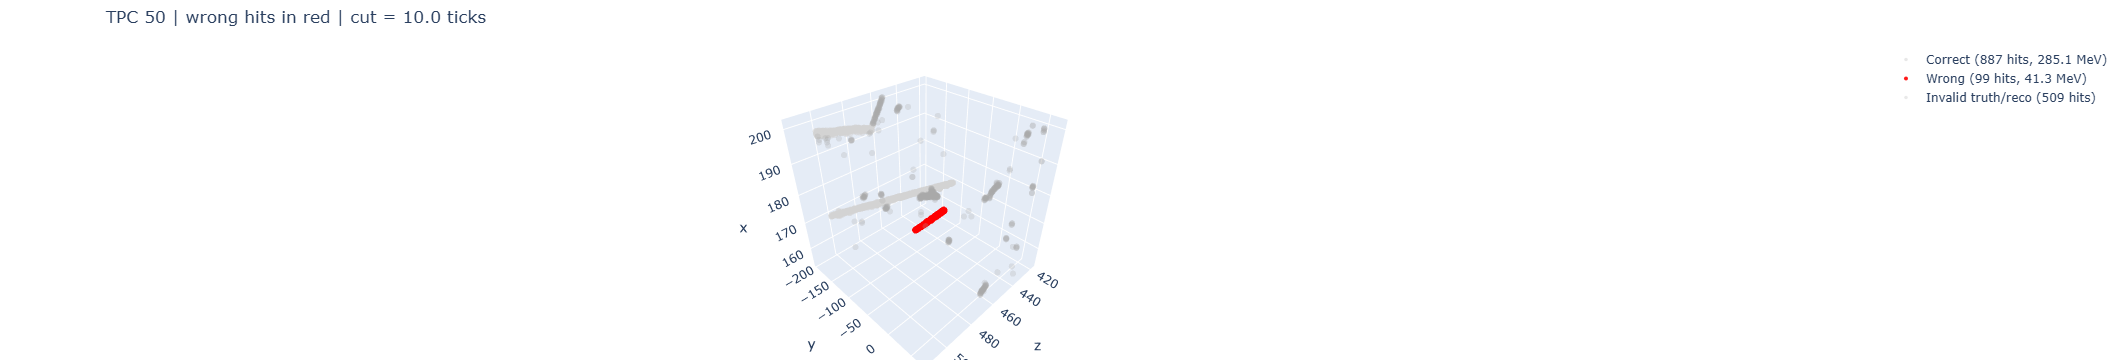

TPC 50
Residual cut                 : 10.00 ticks (160 ns)
Finite truth+reco hits       : 986
Wrong hits                   : 99
Correct energy               : 285.0816 MeV
Wrong energy                 : 41.3023 MeV
Correct energy fraction      : 87.35%
Wrong energy fraction        : 12.65%
saved wrong_hits_lab105_TPC50_rescued.html | wrong hits 99 (41.3 MeV, 12.65%)


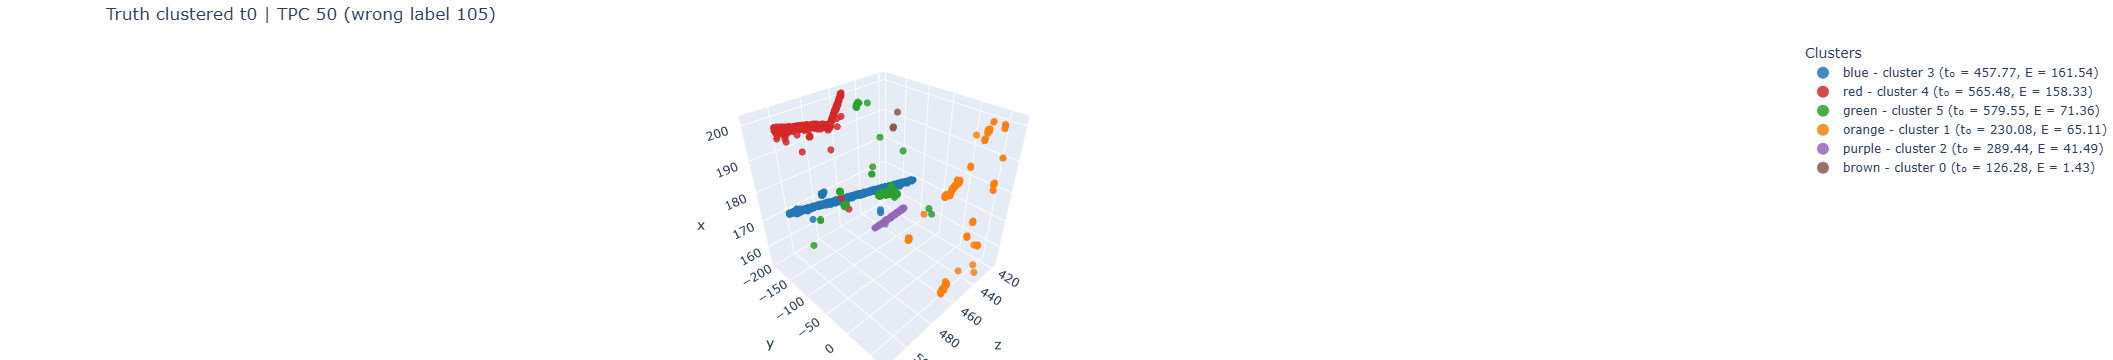

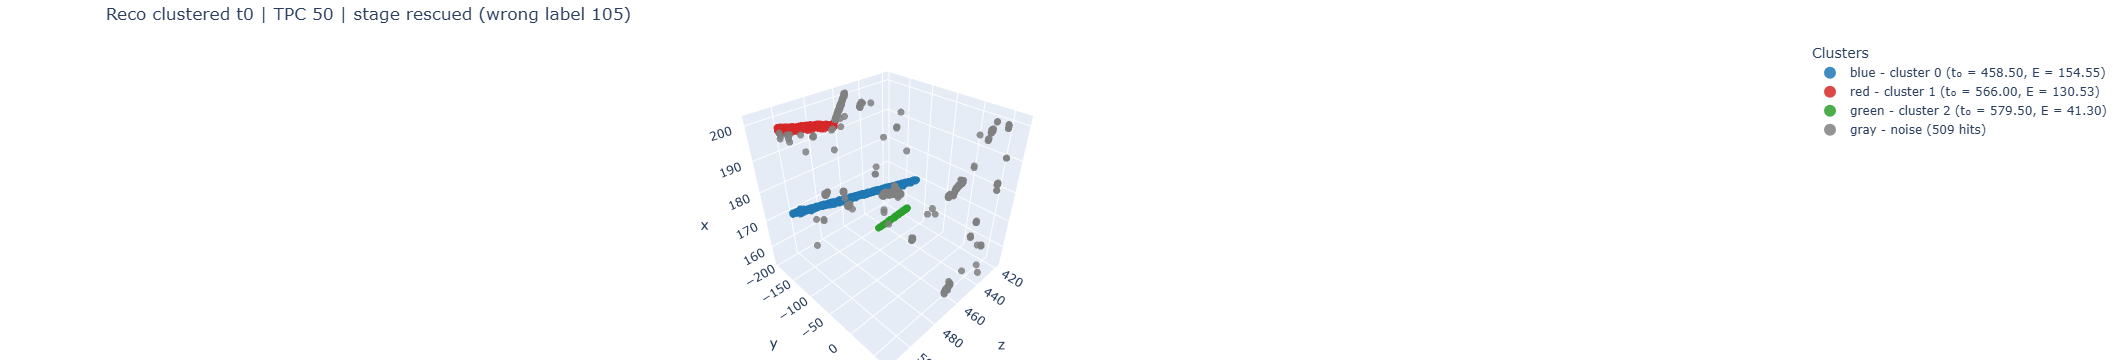

In [25]:
# 3D displays for the chosen wrong example (interactive; HTML saved next to the notebook).
_ns_for_plot = dict(globals())
_ns_for_plot["hit_timestamps"] = np.asarray(STAGE_SNAPSHOTS[WRONG_STAGE], dtype=np.float64)

SAVE_HTML = f"wrong_hits_lab{EX_LAB}_TPC{WRONG_TPC_ID}_{WRONG_STAGE}.html"
wrong_hits_plot = tp.plot_wrong_hits_from_namespace(
    _ns_for_plot,
    TPCid=WRONG_TPC_ID,
    truth_t0=truth_t0,
    residual_cut_ticks=CUT,
    save_path=SAVE_HTML,
    marker_size=3.5,
    correct_color="lightgray",
    wrong_color="red",
    show=True,
)
print(f"saved {SAVE_HTML} | wrong hits {wrong_hits_plot['n_wrong_hits']} "
      f"({wrong_hits_plot['wrong_energy']:.1f} MeV, "
      f"{wrong_hits_plot['wrong_energy_fraction']:.2f}%)")

T0_GROUP_WINDOW_TICKS = 5
truth_t0_plot = tp.plot_truth_from_namespace(
    globals(),
    target_tpc=WRONG_TPC_ID,
    mode="t0",
    time_window=T0_GROUP_WINDOW_TICKS,
    convert_t0_to_matching_ticks=True,
    title=f"Truth clustered t0 | TPC {WRONG_TPC_ID} (wrong label {EX_LAB})",
    save_path=f"truth_t0_lab{EX_LAB}_TPC{WRONG_TPC_ID}.html",
    show=True,
)

_tpc_mask = hitTPCid == int(WRONG_TPC_ID)
_reco_t0 = np.asarray(STAGE_SNAPSHOTS[WRONG_STAGE], dtype=np.float64)
_reco_t0_safe = np.where(np.isfinite(_reco_t0), _reco_t0, -1.0)
_reco_labels_tpc = pt.group_hits_by_time(_reco_t0_safe[_tpc_mask], time_window=T0_GROUP_WINDOW_TICKS)
pt.plot_3d_clusters_with_t0(
    x=xset[_tpc_mask], y=yset[_tpc_mask], z=zset[_tpc_mask],
    labels=_reco_labels_tpc,
    t0s=_reco_t0_safe[_tpc_mask],
    energies=e_pos[_tpc_mask],
    title=f"Reco clustered t0 | TPC {WRONG_TPC_ID} | stage {WRONG_STAGE} (wrong label {EX_LAB})",
    save_path=f"reco_t0_lab{EX_LAB}_TPC{WRONG_TPC_ID}_{WRONG_STAGE}.html",
)

TPC 50 (label 105, stage rescued):
Total energy in TPC 50: 499.27


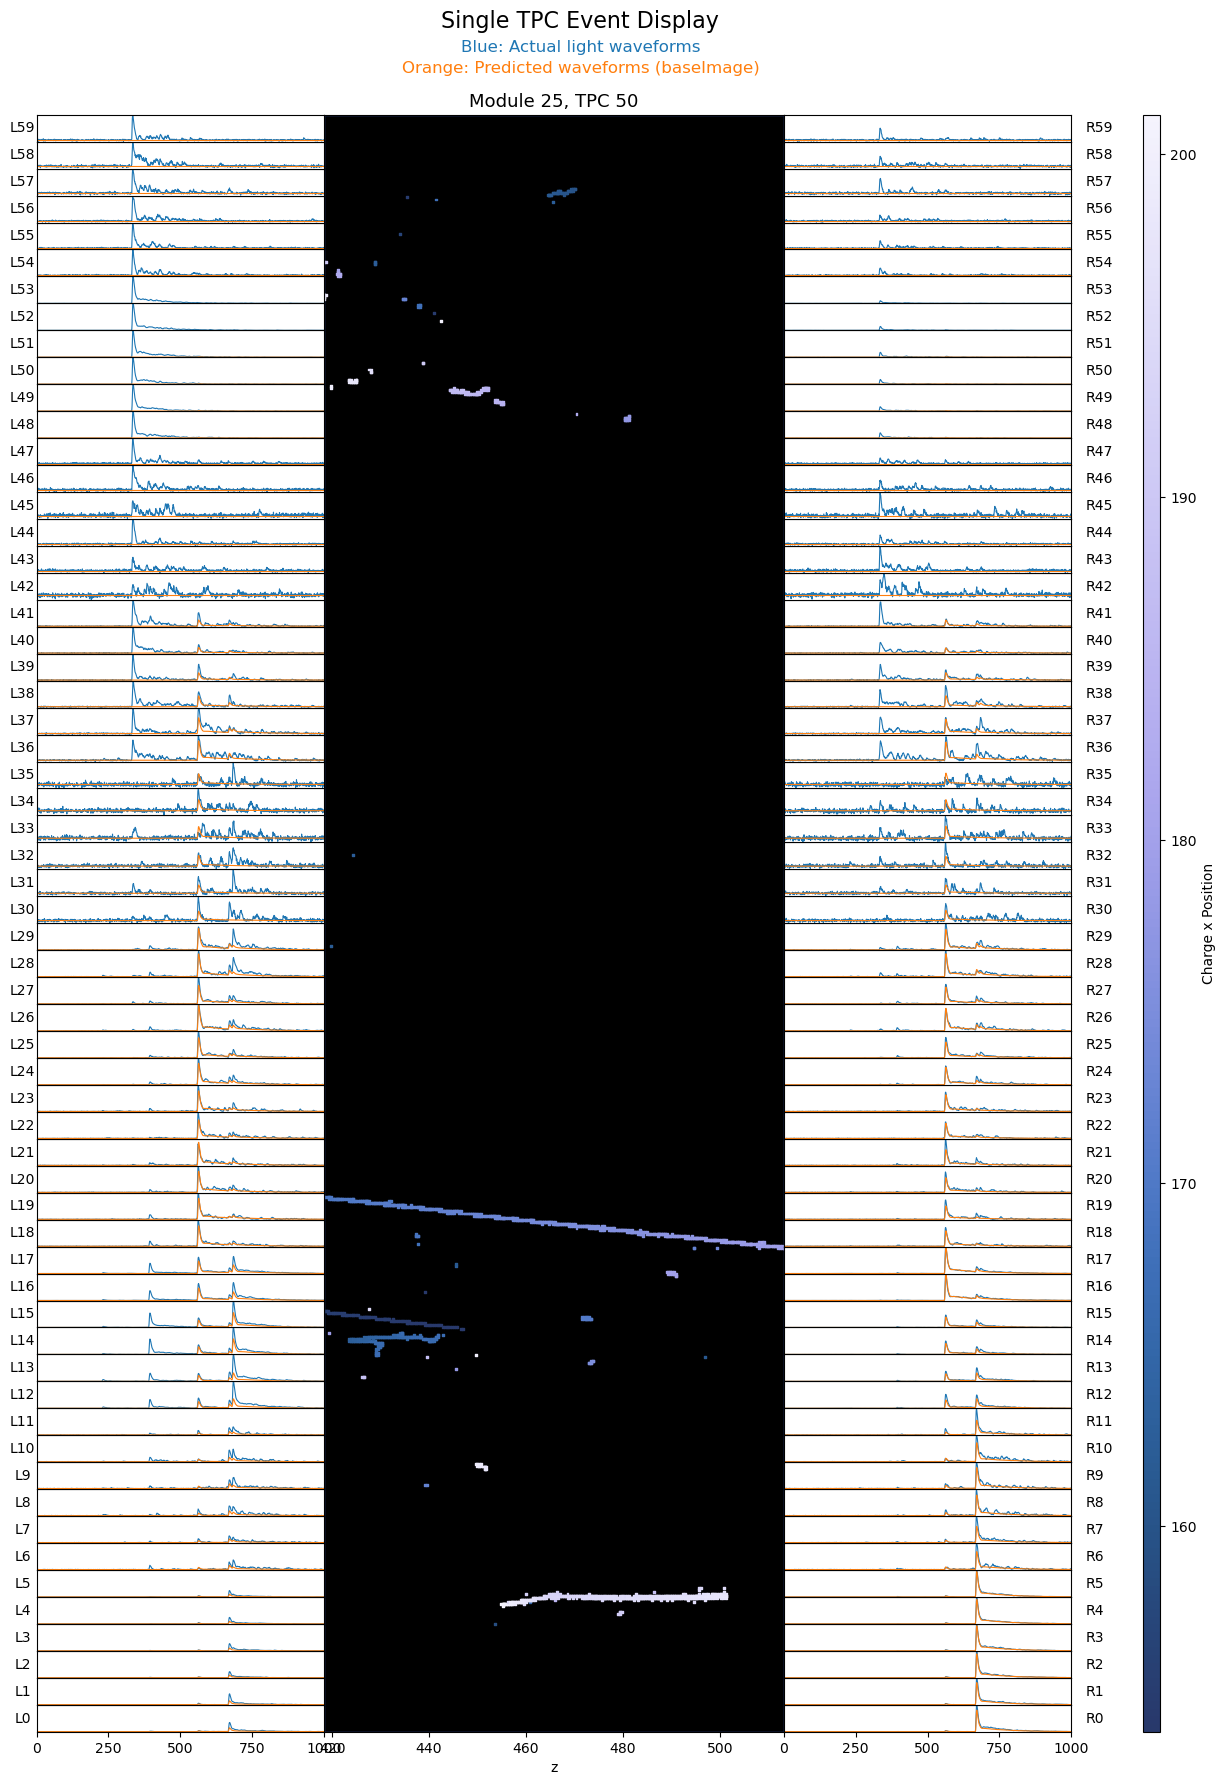

In [26]:
# 2D light+charge comparison for every TPC the wrong example spans, at the chosen stage.
for _c in K["tpcs"]:
    print(f"TPC {_c} (label {EX_LAB}, stage {FIG_STAGE}):")
    plot_tpc_light_and_charge(
        ev_id=ev_id,
        TPCid=int(_c),
        hits_full_ev=hits_evt,
        actual=fullLightWaveform[int(_c)],
        predicted=STAGE_BASEIMAGES[FIG_STAGE][int(_c)],
        geom_map=geom_map,
        individualScaling=False,
    )

## Notes

- **Re-tuning loop**: edit knobs → run **RESET** → run trigger → Stage A → Stage B → N=1 →
  adoption → picker/displays. The front stage (and truth) never need re-running for the same event.
- **Sigma A/B (39 events, measured)**: all-Poisson rescue 97.52%/96.93% (phase-1/final);
  all-model (z=8) 93.51%/94.72% — model-weighted scans break correct placements;
  all-model + 10% stay-margin 96.70%/96.28%. Hence: Poisson weights always; SIGMA_MODE
  only switches the trigger/display z. The cosine arm is sigma-independent.
- Other knobs (from the 39-event study): `COS_CUT` 0.75 (raising to 0.80 buys catch at more
  false pauses), `EXCESS_GATE` 500 and `N_CH_FIRE` 3, `GROUP_DT` 5, `MAX_N` 3.
  `CLIP` 60780 is physical, not a tuning knob.
- Reference numbers (39 events, defaults): trigger catches ~50% of wrong placements at ~12%
  false-pause; Stage A fixes 64% of wrong members at 3.1% breakage; Stage B detach precision ~51%;
  N=1 moves 37/37 correct. Phase-1 accuracy 95.07% → 97.52%.
- Detached parts are **unassigned** here (new cluster ids); in the full pipeline they are re-placed
  by Phase 2 (E >= 50 MeV) or Phase 3. That is why the assigned-energy fraction dips after adoption.
- The wrong-example table's `verdict` column: FIXED / BROKEN / still wrong / ok — computed from the
  label-median t0 vs energy-weighted median truth with the strict +-10-tick definition.
- Batch equivalent of this notebook: `testing/overflow_rescue_pipeline.py` (adds Phase 2 + V2 and
  baseline-vs-rescued double pass); scorer: `testing/rescue_pipe_score.py`.